# E2 / CV — os cinco métodos sob CV 5-fold por paciente

Etapa **anterior** ao treino final (`e2_01_ssl.ipynb`), no molde do `e1_02_cv.ipynb`. Mesmos métodos (+ `mt-temporal-prev3`, vizinho $t-3$, e `dtc-trus`, cuja etapa 1 é o `supervised` do mesmo fold), mesmos
lotes (8 rotulados + 8 centrais não rotulados) e mesmos lr/wd congelados do E1.

**Rodada k:** treina nos folds $\neq k$ do desenvolvimento (rótulos + todo frame nunca anotado **só desses
vídeos**), escolhe o checkpoint pela validação fixa (`val/dice_patient`) e avalia no fold $k$
(`eval_set = cv`). O teste INCA e o UNM não são carregados: eles ficam para o treino final.

**Agregação:** frames → paciente → média dos pacientes do fold → média ± desvio (ddof=1) entre os 5 folds.
As comparações entre métodos são **pareadas por fold** (mesmos pacientes retidos, mesma seed).

> O desvio entre folds mistura a sensibilidade à partição com o ruído do próprio treino (re-runs idênticos
> já divergiram ~0,10 de Dice no X1). Os folds compartilham pacientes de treino, então não são réplicas
> independentes: o desvio **não** é um erro-padrão.

Config: `configs/sweep/e2-cv.yaml`; lógica: `src/sweeps/e2.py` (`E2CVSweep`).

In [1]:
%load_ext autoreload
%autoreload 2

In [9]:
import sys
sys.path.append("../../../")

import matplotlib.pyplot as plt
import pandas as pd

from src.evaluation import METRIC_NAMES, aggregate_per_patient, paired_fold_differences, summarize_over_folds
from src.sweep import Sweep, submit_sweep, sweep_status, watch_sweep

SWEEP_CONFIG = "configs/sweep/e2-cv.yaml"

# Grade. Trocar aqui NAO edita o YAML: vira `--set axes.<eixo>=[...]` no processo do tmux.
ARCHS = ["deeplabv3plus"]
POLICIES = ["global"]                # ["global", "same_video"] para comparar a origem dos nao rotulados
SEEDS = [42]
REFERENCE_METHOD = "supervised"
METHOD_ORDER = ["supervised", "fixmatch", "meanteacher", "mt-temporal-prev", "mt-temporal-prev3", "mt-temporal-bi", "mt-temporal-proto-teacher", "mt-temporal-proto-student", "mt-temporal-nomt", "dtc-trus"]

OVERRIDES = {"axes.arch": ARCHS, "axes.unlabeled_policy": POLICIES, "axes.seed": SEEDS}
sweep = Sweep(SWEEP_CONFIG, overrides=OVERRIDES)
sweep.plan_summary()

,run_id,seed,arch,unlabeled_policy,fold,method,status,host
0,deeplabv3plus-supervised-global-f0-s42,42,deeplabv3plus,global,0,supervised,done (na CSV),dl05
1,deeplabv3plus-fixmatch-global-f0-s42,42,deeplabv3plus,global,0,fixmatch,done (na CSV),dl05
2,deeplabv3plus-meanteacher-global-f0-s42,42,deeplabv3plus,global,0,meanteacher,done (na CSV),dl05
3,deeplabv3plus-mt-temporal-prev-global-f0-s42,42,deeplabv3plus,global,0,mt-temporal-prev,done (na CSV),dl05
4,deeplabv3plus-mt-temporal-bi-global-f0-s42,42,deeplabv3plus,global,0,mt-temporal-bi,done (na CSV),dl05
5,deeplabv3plus-mt-temporal-prev3-global-f0-s42,42,deeplabv3plus,global,0,mt-temporal-prev3,done (na CSV),dl05
6,deeplabv3plus-mt-temporal-proto-teacher-global...,42,deeplabv3plus,global,0,mt-temporal-proto-teacher,done (na CSV),dl05
7,deeplabv3plus-mt-temporal-proto-student-global...,42,deeplabv3plus,global,0,mt-temporal-proto-student,done (na CSV),dl05
8,deeplabv3plus-mt-temporal-nomt-global-f0-s42,42,deeplabv3plus,global,0,mt-temporal-nomt,done (na CSV),dl05
9,deeplabv3plus-dtc-trus-global-f0-s42,42,deeplabv3plus,global,0,dtc-trus,done (na CSV),dl05


## Execução

O treino roda numa sessão tmux (`e2-cv`); fechar o notebook não o interrompe. 30 runs por (arch, política, seed).

In [10]:
sweep_status(SWEEP_CONFIG, overrides=OVERRIDES)

,run_id,seed,arch,unlabeled_policy,fold,method,status,host
0,deeplabv3plus-supervised-global-f0-s42,42,deeplabv3plus,global,0,supervised,done (na CSV),dl05
1,deeplabv3plus-fixmatch-global-f0-s42,42,deeplabv3plus,global,0,fixmatch,done (na CSV),dl05
2,deeplabv3plus-meanteacher-global-f0-s42,42,deeplabv3plus,global,0,meanteacher,done (na CSV),dl05
3,deeplabv3plus-mt-temporal-prev-global-f0-s42,42,deeplabv3plus,global,0,mt-temporal-prev,done (na CSV),dl05
4,deeplabv3plus-mt-temporal-bi-global-f0-s42,42,deeplabv3plus,global,0,mt-temporal-bi,done (na CSV),dl05
5,deeplabv3plus-mt-temporal-prev3-global-f0-s42,42,deeplabv3plus,global,0,mt-temporal-prev3,done (na CSV),dl05
6,deeplabv3plus-mt-temporal-proto-teacher-global...,42,deeplabv3plus,global,0,mt-temporal-proto-teacher,done (na CSV),dl05
7,deeplabv3plus-mt-temporal-proto-student-global...,42,deeplabv3plus,global,0,mt-temporal-proto-student,done (na CSV),dl05
8,deeplabv3plus-mt-temporal-nomt-global-f0-s42,42,deeplabv3plus,global,0,mt-temporal-nomt,done (na CSV),dl05
9,deeplabv3plus-dtc-trus-global-f0-s42,42,deeplabv3plus,global,0,dtc-trus,done (na CSV),dl05


In [11]:
# submit_sweep(SWEEP_CONFIG, overrides=OVERRIDES)

In [12]:
watch_sweep(SWEEP_CONFIG, overrides=OVERRIDES)

e2-cv: 50/50 celulas concluidas (16:50:15)
                                               run_id  seed          arch unlabeled_policy  fold                    method        status host
               deeplabv3plus-supervised-global-f0-s42    42 deeplabv3plus           global     0                supervised done (na CSV) dl05
                 deeplabv3plus-fixmatch-global-f0-s42    42 deeplabv3plus           global     0                  fixmatch done (na CSV) dl05
              deeplabv3plus-meanteacher-global-f0-s42    42 deeplabv3plus           global     0               meanteacher done (na CSV) dl05
         deeplabv3plus-mt-temporal-prev-global-f0-s42    42 deeplabv3plus           global     0          mt-temporal-prev done (na CSV) dl05
           deeplabv3plus-mt-temporal-bi-global-f0-s42    42 deeplabv3plus           global     0            mt-temporal-bi done (na CSV) dl05
        deeplabv3plus-mt-temporal-prev3-global-f0-s42    42 deeplabv3plus           global     0         

## Resultados por fold

In [13]:
results = sweep.load_results()
results = results[results.arch.isin(ARCHS) & results.unlabeled_policy.isin(POLICIES) & results.seed.isin(SEEDS)]
assert set(results.eval_set) == {"cv"}, "o CV so pode ter linhas do fold retido"

BY = ["arch", "unlabeled_policy", "method"]
per_fold = aggregate_per_patient(results, group_columns=BY + ["fold", "seed"])
per_fold["method"] = pd.Categorical(per_fold["method"], METHOD_ORDER, ordered=True)
per_fold.pivot_table(index="fold", columns="method", values="dice", observed=True).round(4)

method,supervised,fixmatch,meanteacher,mt-temporal-prev,mt-temporal-prev3,mt-temporal-bi,mt-temporal-proto-teacher,mt-temporal-proto-student,mt-temporal-nomt,dtc-trus
fold,,,,,,,,,,
0,0.8547,0.8557,0.8593,0.8613,0.8569,0.8590,0.8625,0.8541,0.8545,0.0039
1,0.8638,0.5564,0.8765,0.8732,0.8765,0.8758,0.8778,0.8722,0.8697,0.0000
2,0.8732,0.0447,0.8739,0.8713,0.8726,0.8724,0.8686,0.8692,0.8657,0.7367
3,0.8518,0.4338,0.8530,0.8466,0.8434,0.8549,0.8415,0.8504,0.8545,0.0216
4,0.8631,0.4436,0.8655,0.8594,0.8676,0.8689,0.8668,0.8644,0.8578,0.0000


## Média ± desvio entre folds

In [14]:
summary = summarize_over_folds(per_fold, BY).sort_values(BY)
table = summary[BY + ["n_folds"]].copy()
for metric in METRIC_NAMES:
    table[metric] = [f"{m:.4f} ± {s:.4f}" for m, s in zip(summary[f"{metric}_mean"], summary[f"{metric}_std"])]
table.reset_index(drop=True)

,arch,unlabeled_policy,method,n_folds,dice,iou,assd,hd95
0,deeplabv3plus,global,supervised,5,0.8613 ± 0.0085,0.7620 ± 0.0120,1.3090 ± 0.0597,5.4144 ± 0.3353
1,deeplabv3plus,global,fixmatch,5,0.4669 ± 0.2911,0.3605 ± 0.2620,36.4345 ± 44.5666,63.7134 ± 66.3843
2,deeplabv3plus,global,meanteacher,5,0.8656 ± 0.0098,0.7682 ± 0.0136,1.2798 ± 0.0940,5.2682 ± 0.6294
3,deeplabv3plus,global,mt-temporal-prev,5,0.8624 ± 0.0107,0.7632 ± 0.0149,1.3561 ± 0.1338,5.7527 ± 0.6960
4,deeplabv3plus,global,mt-temporal-prev3,5,0.8634 ± 0.0133,0.7650 ± 0.0179,1.3313 ± 0.1206,5.5795 ± 0.6741
5,deeplabv3plus,global,mt-temporal-bi,5,0.8662 ± 0.0089,0.7685 ± 0.0122,1.2551 ± 0.0930,5.0307 ± 0.5513
6,deeplabv3plus,global,mt-temporal-proto-teacher,5,0.8634 ± 0.0135,0.7651 ± 0.0186,1.3147 ± 0.1360,5.5313 ± 0.6432
7,deeplabv3plus,global,mt-temporal-proto-student,5,0.8621 ± 0.0095,0.7628 ± 0.0132,1.4326 ± 0.3191,5.4413 ± 0.4797
8,deeplabv3plus,global,mt-temporal-nomt,5,0.8604 ± 0.0069,0.7603 ± 0.0095,1.4727 ± 0.3528,5.6930 ± 0.3736
9,deeplabv3plus,global,dtc-trus,5,0.1524 ± 0.3268,0.1207 ± 0.2624,217.2254 ± 147.5476,229.1756 ± 141.6724


## Diferença pareada por fold contra o supervisionado

Positivo = maior que o supervisionado (melhor para Dice/IoU, pior para ASSD/HD95). `vitórias` conta em
quantos folds o método supera a referência em Dice.

In [15]:
diffs = paired_fold_differences(per_fold, by="method", reference=REFERENCE_METHOD,
                                group_columns=["arch", "unlabeled_policy", "seed"])
display(diffs.pivot_table(index="fold", columns="method", values="dice", observed=True).round(4))

diff_summary = summarize_over_folds(diffs, BY)
wins = diffs.assign(win=diffs.dice > 0).groupby(BY, observed=True).win.sum().rename("vitórias (Dice)")
diff_summary = diff_summary.merge(wins.reset_index(), on=BY)
diff_summary[BY + ["n_folds", "vitórias (Dice)", "dice_mean", "dice_std", "hd95_mean", "hd95_std"]].round(4)

method,fixmatch,meanteacher,mt-temporal-prev,mt-temporal-prev3,mt-temporal-bi,mt-temporal-proto-teacher,mt-temporal-proto-student,mt-temporal-nomt,dtc-trus
fold,,,,,,,,,
0,0.0010,0.0045,0.0066,0.0022,0.0043,0.0077,-0.0007,-0.0003,-0.8509
1,-0.3074,0.0127,0.0094,0.0126,0.0120,0.0140,0.0084,0.0059,-0.8638
2,-0.8285,0.0006,-0.0019,-0.0006,-0.0008,-0.0047,-0.0041,-0.0075,-0.1365
3,-0.4180,0.0012,-0.0052,-0.0083,0.0031,-0.0103,-0.0014,0.0027,-0.8302
4,-0.4195,0.0024,-0.0037,0.0045,0.0059,0.0037,0.0013,-0.0053,-0.8631


,arch,unlabeled_policy,method,n_folds,vitórias (Dice),dice_mean,dice_std,hd95_mean,hd95_std
0,deeplabv3plus,global,fixmatch,5,1,-0.3945,0.2973,58.2990,66.6512
1,deeplabv3plus,global,meanteacher,5,5,0.0043,0.0049,-0.1462,0.6091
2,deeplabv3plus,global,mt-temporal-prev,5,2,0.0010,0.0065,0.3383,0.5340
3,deeplabv3plus,global,mt-temporal-prev3,5,3,0.0021,0.0076,0.1651,0.4864
4,deeplabv3plus,global,mt-temporal-bi,5,4,0.0049,0.0047,-0.3837,0.5274
5,deeplabv3plus,global,mt-temporal-proto-teacher,5,3,0.0021,0.0097,0.1169,0.6598
6,deeplabv3plus,global,mt-temporal-proto-student,5,2,0.0007,0.0047,0.0269,0.5339
7,deeplabv3plus,global,mt-temporal-nomt,5,2,-0.0009,0.0055,0.2786,0.5540
8,deeplabv3plus,global,dtc-trus,5,0,-0.7089,0.3203,223.7612,141.3619


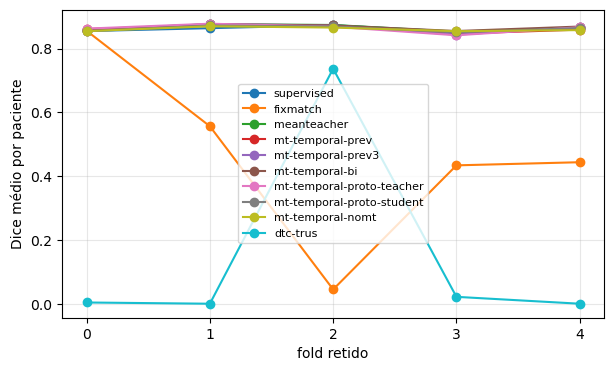

In [16]:
fig, ax = plt.subplots(figsize=(7, 4))
for method, group in per_fold.groupby("method", observed=True):
    group = group.sort_values("fold")
    ax.plot(group.fold, group.dice, marker="o", label=method)
ax.set_xlabel("fold retido"); ax.set_ylabel("Dice médio por paciente"); ax.set_xticks(range(5))
ax.legend(fontsize=8); ax.grid(alpha=0.3)

## Custo por run (média entre folds)

In [17]:
resources = sweep.plan.load_resources()
if len(resources):
    resources = resources[resources.arch.isin(ARCHS) & resources.unlabeled_policy.isin(POLICIES) & resources.seed.isin(SEEDS)]
    cols = [c for c in ["fit_wall_s", "total_fit_wall_s", "s_per_step_mean", "data_wait_frac", "vram_train_peak_gb", "best_step"] if c in resources]
    display(resources.groupby(BY)[cols].agg(["mean", "std"]).round(3))

fit_wall_s           \
                                                               mean      std   
arch          unlabeled_policy method                                          
deeplabv3plus global           dtc-trus                     657.420  764.948   
                               fixmatch                     570.761  283.886   
                               meanteacher                  462.152  135.715   
                               mt-temporal-bi               755.549  388.892   
                               mt-temporal-nomt             646.876  208.979   
                               mt-temporal-prev             681.105  157.385   
                               mt-temporal-prev3            561.134  154.911   
                               mt-temporal-proto-student    829.283  299.912   
                               mt-temporal-proto-teacher    683.874  124.356   
                               supervised                   539.568  111.150   

                                                         total_fit_wall_s  \
                                                                     mean   
arch          unlabeled_policy method                                       
deeplabv3plus global           dtc-trus                          1196.988   
                               fixmatch                           570.761   
                               meanteacher                        462.152   
                               mt-temporal-bi                     755.549   
                               mt-temporal-nomt                   646.876   
                               mt-temporal-prev                   681.105   
                               mt-temporal-prev3                  561.134   
                               mt-temporal-proto-student          829.283   
                               mt-temporal-proto-teacher          683.874   
                               supervised                         539.568   

                                                                   \
                                                              std   
arch          unlabeled_policy method                               
deeplabv3plus global           dtc-trus                   805.547   
                               fixmatch                   283.886   
                               meanteacher                135.715   
                               mt-temporal-bi             388.892   
                               mt-temporal-nomt           208.979   
                               mt-temporal-prev           157.385   
                               mt-temporal-prev3          154.911   
                               mt-temporal-proto-student  299.912   
                               mt-temporal-proto-teacher  124.356   
                               supervised                 111.150   

                                                         s_per_step_mean  \
                                                                    mean   
arch          unlabeled_policy method                                      
deeplabv3plus global           dtc-trus                            0.183   
                               fixmatch                            0.105   
                               meanteacher                         0.093   
                               mt-temporal-bi                      0.158   
                               mt-temporal-nomt                    0.137   
                               mt-temporal-prev                    0.138   
                               mt-temporal-prev3                   0.138   
                               mt-temporal-proto-student           0.152   
                               mt-temporal-proto-teacher           0.141   
                               supervised                          0.083   

                                                                 \
                                                            